# Lecture 5 — Applications of Phase Estimation (UnitaryLab companion)

This notebook demonstrates two applications of QPE with the UnitaryLab simulator
(v1.1.4). Run top to bottom.

Contents:
1. Ground-state energy of a small Hamiltonian via QPE
2. Amplitude-estimation scaling: error $\sim 1/Q$ (Heisenberg) vs. $1/\sqrt Q$ (sampling)

In [1]:
import numpy as np
from unitarylab.core import Circuit

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

rng = np.random.default_rng(5)

## 1. Ground-state energy via QPE

Take a diagonal single-qubit Hamiltonian $H = \mathrm{diag}(E_0, E_1)$ with
eigenstates $|0\rangle, |1\rangle$. The time-evolution operator is
$U = e^{-iHt} = \mathrm{diag}(e^{-iE_0 t}, e^{-iE_1 t})$. QPE on eigenstate
$|1\rangle$ recovers the phase $\varphi$ with $e^{-iE_1 t} = e^{2\pi i\varphi}$,
i.e. $E_1 = -2\pi\varphi/t \pmod{2\pi/t}$.

We *choose* $E_1$ and the evolution time $t$ so that $\varphi = E_1 t/(2\pi)$ lands
exactly on the QPE grid, then recover $E_1$ from the measured phase. We reuse the
same QPE building blocks as Lecture 4: for the diagonal $U$, controlled-$U^{2^r}$
on eigenstate $|1\rangle$ is simply a controlled phase.

In [2]:
def _qft_into(qc, qubits):
    m = len(qubits)
    for i in range(m):
        qc.h(qubits[i])
        for j in range(i+1, m):
            qc.cp(2*np.pi/2**(j - i + 1), qubits[j], qubits[i])
    for i in range(m//2):
        qc.swap(qubits[i], qubits[m-1-i])

def qpe_phase(varphi, t_qubits):
    '''QPE for U = diag(1, e^{2 pi i varphi}) on eigenstate |1>. Returns (phi_est, prob).'''
    n = t_qubits + 1
    sys = t_qubits
    qc = Circuit(n, name='qpe')
    qc.x(sys)
    for r in range(t_qubits):
        qc.h(r)
    for r in range(t_qubits):
        qc.cp(2*np.pi*varphi*(2**r), r, sys)
    inv = Circuit(t_qubits); _qft_into(inv, list(range(t_qubits-1, -1, -1)))
    qc.append(inv.dagger(), target=list(range(t_qubits)))
    probs = qc.execute(backend='numpy', dtype=np.complex128).probabilities
    counting = {}
    for k, p in probs.items():
        counting[k[1:]] = counting.get(k[1:], 0.0) + p   # drop system qubit (leftmost)
    best = max(counting, key=counting.get)
    return int(best, 2) / 2**t_qubits, counting[best]

# Choose a Hamiltonian and evolution time so the ground-state phase is dyadic.
E1 = 1.5                      # excited-state energy (ground state E0 = 0 here)
t_evolve = np.pi / 3          # evolution time; varphi = E1 * t_evolve / (2 pi)
varphi = (E1 * t_evolve / (2*np.pi)) % 1.0
print('target varphi =', varphi, ' (=', round(varphi, 6), ')')

t_qubits = 3
phi_est, prob = qpe_phase(varphi, t_qubits)
E1_recovered = 2*np.pi*phi_est / t_evolve
print(f'QPE phi_est = {phi_est}  (prob {prob:.4f})')
print(f'recovered E1 = {E1_recovered:.6f}  (true {E1})')
assert abs(phi_est - varphi) < 1e-9 and prob > 0.999
assert abs(E1_recovered - E1) < 1e-9
print('asserts passed: eigenphase and energy recovered exactly')

target varphi = 0.25  (= 0.25 )
QPE phi_est = 0.25  (prob 1.0000)
recovered E1 = 1.500000  (true 1.5)
asserts passed: eigenphase and energy recovered exactly


The ground-state energy here is $E_0 = 0$ (phase $0$ on $|0\rangle$); running QPE
on $|0\rangle$ would return $\varphi = 0$. The interesting eigenvalue is the
excited energy $E_1 = 1.5$, recovered exactly because we engineered $\varphi = 1/4$
to sit on the 3-bit grid.

## 2. Amplitude estimation: $1/Q$ vs. $1/\sqrt Q$

Amplitude estimation is QPE applied to the Grover iterate: to estimate an
amplitude $a=\sin^2\theta$ it uses $Q$ applications of the oracle and returns an
estimate with error $\mathcal{O}(1/Q)$ — a quadratic (Heisenberg) speedup over
classical Monte Carlo sampling, whose error scales as $1/\sqrt Q$.

We illustrate the two scalings side by side. The QPE-based estimate of a phase
$\theta$ with $t$ counting qubits (hence $Q=2^t$ oracle calls) has error bounded
by the grid spacing $\pi/2^t \sim 1/Q$; classical sampling of the same amplitude
has statistical error $\sim 1/\sqrt Q$. We compute both empirically.

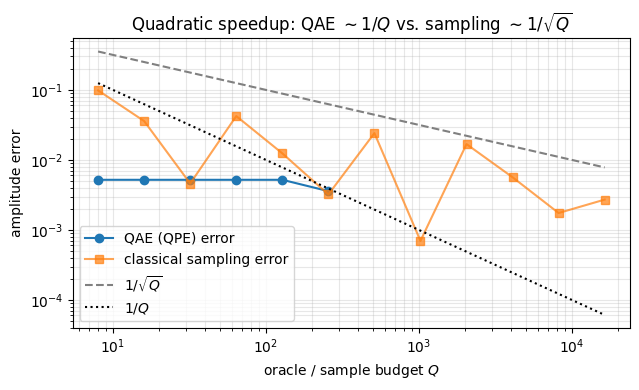

QAE errors  : ['5.2e-03', '5.2e-03', '5.2e-03', '5.2e-03', '5.2e-03', '3.6e-03']
sampling err: ['9.8e-02', '3.6e-02', '4.6e-03', '4.2e-02', '1.2e-02', '3.2e-03'] ...
assert passed: QAE error at largest budget beats the 1/sqrt(Q) envelope


In [3]:
# True amplitude a = sin^2(theta) via a Ry rotation angle.
theta_true = 0.4                       # so amplitude a = sin^2(theta_true)
a_true = np.sin(theta_true)**2

# --- Quantum (amplitude estimation ~ QPE): error ~ 1/Q ---
# The Grover-iterate eigenphase is 2*theta/(2 pi). We estimate it with t counting
# qubits and read the grid error, which scales as the grid spacing 1/2^t = 1/Q.
q_qae, err_qae = [], []
for t in range(3, 9):
    varphi = (2*theta_true) / (2*np.pi)          # eigenphase of the Grover iterate
    phi_est, _ = qpe_phase(varphi % 1.0, t)
    theta_est = np.pi * phi_est                   # invert varphi = 2 theta / (2 pi)
    a_est = np.sin(theta_est)**2
    q_qae.append(2**t)
    err_qae.append(abs(a_est - a_true))

# --- Classical sampling: error ~ 1/sqrt(Q) ---
q_mc, err_mc = [], []
for Q in [2**t for t in range(3, 15)]:
    samples = rng.random(Q) < a_true
    a_hat = samples.mean()
    q_mc.append(Q)
    err_mc.append(abs(a_hat - a_true))

plt.figure(figsize=(6.5,4))
plt.loglog(q_qae, np.maximum(err_qae, 1e-6), 'o-', label='QAE (QPE) error')
plt.loglog(q_mc, err_mc, 's-', alpha=0.7, label='classical sampling error')
Q = np.array(q_mc, float)
plt.loglog(Q, 1/np.sqrt(Q), '--', color='gray', label=r'$1/\sqrt{Q}$')
plt.loglog(Q, 1/Q, ':', color='k', label=r'$1/Q$')
plt.xlabel('oracle / sample budget $Q$'); plt.ylabel('amplitude error')
plt.title('Quadratic speedup: QAE $\\sim 1/Q$ vs. sampling $\\sim 1/\\sqrt{Q}$')
plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.tight_layout(); plt.show()

print('QAE errors  :', [f'{e:.1e}' for e in err_qae])
print('sampling err:', [f'{e:.1e}' for e in err_mc[:6]], '...')
# QAE error at the largest budget should beat the 1/sqrt(Q) sampling envelope there.
assert err_qae[-1] < 1/np.sqrt(q_qae[-1])
print('assert passed: QAE error at largest budget beats the 1/sqrt(Q) envelope')

### Your turn
- Change `E1` and `t_evolve` so that $\varphi$ is *not* dyadic and observe QPE
  return a peaked (not certain) distribution — then average to estimate $E_1$.
- Increase the counting qubits in the QAE loop and confirm the error keeps
  halving with each extra qubit (the $1/Q$ law).
- Replace the diagonal $H$ with $H = \tfrac12(I - X)$ (eigenstates $|\pm\rangle$)
  and adapt the eigenstate preparation with a Hadamard.